# K-Nearest Neighbors (KNN): Predicting Violent Crime Levels

## Project Objective
Analyze Indian districts based on historical reported crime patterns using regression, classification, and clustering to identify comparatively lower/higher reported crime levels and groups of districts with similar crime profiles.

This notebook implements a **K-Nearest Neighbors (KNN) Classifier** to predict a district's `Violent Crime Level` (Low, Medium, or High) based entirely on its property and disturbance crimes, and compares it to our previous Decision Tree and Random Forest models.

## Step 1 — Data Loading and Preparation

Because our previously prepared variables (`X_train_clf`, etc.) were stored in the memory of the `data_prep.ipynb` notebook, we will quickly reproduce the exact same classification preprocessing steps here to ensure a fair comparison. 

We will:
1. Load the dataset and remove summary rows.
2. Create the `Violent Crime Score`.
3. Perform the Time-Based Split: Training (2001-2009) and Testing (2010-2012).
4. Calculate the Low/Medium/High tertile thresholds using **only** the training data.
5. Create our classification features and target variables without data leakage.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
file_path = '../data/factors/crime/01_District_wise_crimes_committed_IPC_2001_2012.csv'
df = pd.read_csv(file_path)

# Filter summary rows
df_clean = df[~df['DISTRICT'].isin(['TOTAL', 'DELHI UT TOTAL'])].copy()

# Create Project-Defined Composite Score
df_clean['Violent Crime Score'] = (
    df_clean['MURDER'] + 
    df_clean['ATTEMPT TO MURDER'] + 
    df_clean['RAPE'] + 
    df_clean['KIDNAPPING & ABDUCTION']
)

# Time-Based Split
train_df = df_clean[df_clean['YEAR'] <= 2009].copy()
test_df = df_clean[df_clean['YEAR'] >= 2010].copy()

# Calculate classification thresholds from TRAINING data only
lower_threshold = train_df['Violent Crime Score'].quantile(0.33)
upper_threshold = train_df['Violent Crime Score'].quantile(0.67)

def categorize_crime(score):
    if score <= lower_threshold:
        return 'Low'
    elif score <= upper_threshold:
        return 'Medium'
    else:
        return 'High'

# Apply labels to both sets
train_df['Violent Crime Level'] = train_df['Violent Crime Score'].apply(categorize_crime)
test_df['Violent Crime Level'] = test_df['Violent Crime Score'].apply(categorize_crime)

# Define Features and Target
clf_features = ['THEFT', 'BURGLARY', 'ROBBERY', 'CHEATING', 'RIOTS']
clf_target = 'Violent Crime Level'

# Create final ML variables
X_train_clf = train_df[clf_features]
y_train_clf = train_df[clf_target]

X_test_clf = test_df[clf_features]
y_test_clf = test_df[clf_target]

print("Data preparation complete!")

Data preparation complete!


## Step 2 — What is KNN?

1. **What does KNN mean?** It stands for K-Nearest Neighbors. It is a classification algorithm that predicts the category of a new observation based on the categories of the observations closest to it.
2. **What does "K" mean?** K is the number of neighbors the algorithm will check. If K=5, it looks at the 5 closest observations.
3. **What is a nearest neighbor?** In this context, a neighbor is NOT a geographically nearby district. It is a district that is similar in **mathematical feature space**. (e.g., two districts from opposite sides of the country could be 'neighbors' because they both have exactly 500 thefts and 200 robberies).
4. **How KNN classifies:** It measures the mathematical distance between the new observation and all existing observations, finds the K closest ones, and holds a majority vote.
5. **Why distance matters:** Because the entire model is based purely on measuring distances between numbers.
6. **Why feature scaling is important:** If one feature has huge numbers (like Theft usually in the 1000s) and another has tiny numbers (like Robbery usually in the 10s), the distance calculation will be completely dominated by Theft. We must "scale" the features so they have an equal voice.

### Simple Conceptual Example:
```text
New observation
      ↓
Find K closest observations (in mathematical feature space)
      ↓
Look at their classes
      ↓
Majority class
      ↓
Prediction
```

## Step 3 — Import ML Libraries

We import our standard libraries, along with `StandardScaler` for scaling and `KNeighborsClassifier` for the algorithm.

In [2]:
import matplotlib.pyplot as plt

# Import scaling and algorithm
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 4 — Inspect the prepared data

Let's look at the shape and contents of our datasets before scaling.

In [3]:
# Display shapes
print(f"X_train_clf shape (Training): {X_train_clf.shape}")
print(f"X_test_clf shape (Testing):   {X_test_clf.shape}\n")

# Verify no missing values
print(f"Missing values in training features: {X_train_clf.isnull().sum().sum()}")
print(f"Missing values in testing features:  {X_test_clf.isnull().sum().sum()}\n")

# Display feature names
print("Features used:", list(X_train_clf.columns))

# Display class counts
print("\nTraining Class Counts:")
display(y_train_clf.value_counts())

print("\nTesting Class Counts:")
display(y_test_clf.value_counts())

print("\nFirst 5 rows of X_train_clf:")
display(X_train_clf.head())

X_train_clf shape (Training): (6321, 5)
X_test_clf shape (Testing):   (2276, 5)

Missing values in training features: 0
Missing values in testing features:  0

Features used: ['THEFT', 'BURGLARY', 'ROBBERY', 'CHEATING', 'RIOTS']

Training Class Counts:


Violent Crime Level
Medium    2137
Low       2102
High      2082
Name: count, dtype: int64


Testing Class Counts:


Violent Crime Level
High      900
Medium    716
Low       660
Name: count, dtype: int64


First 5 rows of X_train_clf:


,THEFT,BURGLARY,ROBBERY,CHEATING,RIOTS
0,199,198,41,104,78
1,366,191,16,65,168
2,723,237,14,209,156
3,173,98,4,37,164
4,1021,437,25,220,70


## Step 5 & 6 — Why Feature Scaling Is Required for KNN

KNN uses distance calculations. If one feature has much larger numerical values than another feature (e.g., `THEFT` is 1000-5000, `ROBBERY` is 10-50), it can completely dominate the distance calculation simply because of its scale.

We use `StandardScaler` to put all features on a comparable, standardized mathematical scale.

**IMPORTANT DATA LEAKAGE RULE:**
* We use `fit_transform()` on the training data. This calculates the mean/variance of the training data and applies the scale.
* We use `transform()` ONLY on the test data. We do NOT fit the scaler on the test data, because the model is not allowed to know the future test distribution during training.

In [4]:
# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the training data
X_train_scaled = scaler.fit_transform(X_train_clf)

# Only transform the testing data (using the training data's scale)
X_test_scaled = scaler.transform(X_test_clf)

# Display the scaled training data in a readable dataframe form
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train_clf.columns
)

print("Scaled Training Features (First 5 rows):")
display(X_train_scaled_df.head())

print("\nSimple Verification (Mean should be ~0, Std should be ~1):")
display(X_train_scaled_df.describe().round(2).loc[['mean', 'std']])

Scaled Training Features (First 5 rows):


,THEFT,BURGLARY,ROBBERY,CHEATING,RIOTS
0,-0.258267,0.323568,0.304904,0.142926,-0.086717
1,-0.037360,0.288631,-0.253216,-0.090961,0.606297
2,0.434879,0.518217,-0.297865,0.772621,0.513895
3,-0.292660,-0.175530,-0.521113,-0.258880,0.575496
4,0.829073,1.516413,-0.052293,0.838589,-0.148318



Simple Verification (Mean should be ~0, Std should be ~1):


,THEFT,BURGLARY,ROBBERY,CHEATING,RIOTS
mean,-0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


## Step 7 & 8 — Choose K and Train KNN

We set `K = 5` (using `n_neighbors=5`), meaning the model considers the 5 nearest training observations in feature space when classifying a test observation.

When we call `.fit()`, KNN simply stores the training observations. It does not calculate mathematical weights or tree branches. It literally just plots the points in its mathematical space so it can measure distances later.

In [5]:
# Initialize KNN with K=5
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model using the scaled training data
knn.fit(X_train_scaled, y_train_clf)

print("KNN Classifier successfully trained (stored the points)!")

KNN Classifier successfully trained (stored the points)!


## Step 9 — Make Predictions

We ask our KNN model to look at the scaled future test data (2010–2012 features), find the 5 closest historical training districts for each, and vote on the `Violent Crime Level`. We then place the model's predictions next to what actually happened.

In [6]:
# Use the trained model to predict the scaled testing data
y_pred = knn.predict(X_test_scaled)

# Create a comparison dataframe
comparison_df = pd.DataFrame({
    'Actual': y_test_clf.values,
    'Predicted': y_pred
})

print("Comparison of Actual vs Predicted (First 15 observations):")
display(comparison_df.head(15))

Comparison of Actual vs Predicted (First 15 observations):


,Actual,Predicted
0,High,High
1,High,High
2,High,High
3,High,High
4,High,High
5,High,High
6,Low,Low
7,High,High
8,Medium,Medium
9,High,High


## Step 10 — Evaluate KNN

Because this is a multiclass problem, we use "weighted" averages to account for the exact number of observations in each class.

* **Accuracy:** The proportion of correct predictions.
* **Weighted Precision:** How often predictions for a class were correct.
* **Weighted Recall:** How many actual observations of a class were correctly identified.
* **Weighted F1-score:** A balanced harmonic mean between precision and recall.

In [7]:
# Calculate metrics
accuracy = accuracy_score(y_test_clf, y_pred)
precision = precision_score(y_test_clf, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test_clf, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test_clf, y_pred, average="weighted", zero_division=0)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Weighted Precision:{precision:.4f}")
print(f"Weighted Recall:   {recall:.4f}")
print(f"Weighted F1-score: {f1:.4f}\n")

print("Detailed Classification Report:")
print(classification_report(y_test_clf, y_pred, zero_division=0))

Accuracy:          0.6793
Weighted Precision:0.6742
Weighted Recall:   0.6793
Weighted F1-score: 0.6755

Detailed Classification Report:
              precision    recall  f1-score   support

        High       0.74      0.72      0.73       900
         Low       0.72      0.82      0.77       660
      Medium       0.55      0.50      0.52       716

    accuracy                           0.68      2276
   macro avg       0.67      0.68      0.67      2276
weighted avg       0.67      0.68      0.68      2276



## Step 11 — Confusion Matrix

* **Rows:** The actual true classes.
* **Columns:** The predicted classes.
* **Diagonal:** The correct predictions.
* **Off-Diagonal:** The incorrect predictions.

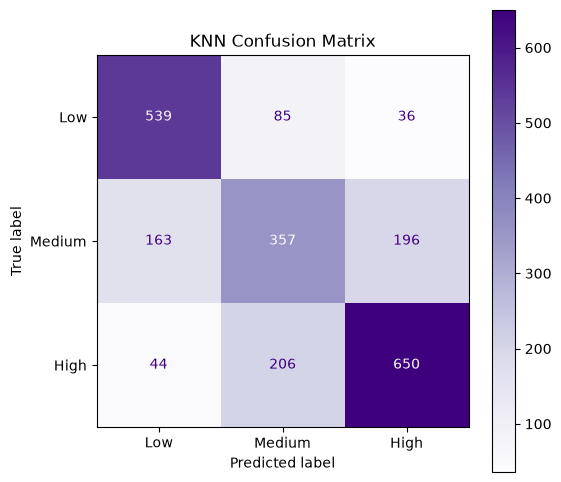

In [8]:
# Create the confusion matrix array
cm = confusion_matrix(
    y_test_clf,
    y_pred,
    labels=["Low", "Medium", "High"]
)

# Display it visually
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Purples')
plt.title("KNN Confusion Matrix")
plt.grid(False)
plt.show()

## Step 12 — Compare KNN with Decision Tree and Random Forest

We previously trained a Decision Tree and a Random Forest on this exact same data. Let's compare their metrics.

*(Note: All three models use the same features, target, training period, and testing period).*

In [9]:
# Create comparison table using our actual variables for KNN, and hardcoded values for DT/RF
comp_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Weighted Precision', 'Weighted Recall', 'Weighted F1-score'],
    'Decision Tree': ['69.11%', '69.56%', '69.11%', '69.31%'],
    'Random Forest': ['70.30%', '69.84%', '70.30%', '70.01%'],
    'KNN': [f"{accuracy*100:.2f}%", f"{precision*100:.2f}%", f"{recall*100:.2f}%", f"{f1*100:.2f}%"]
})

display(comp_df)

,Metric,Decision Tree,Random Forest,KNN
0,Accuracy,69.11%,70.30%,67.93%
1,Weighted Precision,69.56%,69.84%,67.42%
2,Weighted Recall,69.11%,70.30%,67.93%
3,Weighted F1-score,69.31%,70.01%,67.55%


## KNN Limitations

* **Parameter Sensitivity:** KNN depends heavily on the chosen value of K (we simply chose 5).
* **Scaling Sensitivity:** KNN is incredibly sensitive to feature scaling; failing to scale would ruin the model.
* **Computational Cost:** Prediction can become slower with massive datasets because it has to calculate the distance to every single historical training observation to find the closest ones.
* **No Feature Importance:** KNN does not provide a feature importance metric like trees do, so we can't easily see which crime drove the decision.
* **Geographical vs Feature Space:** Results depend strictly on similarity in *crime-feature space*, not actual geographical distance.
* **Data Nature:** Historical reported crime counts are not population-adjusted crime rates, and the target is based on a project-defined Violent Crime Score.

## Model Interpretation

1. **What KNN predicted:** The categorical `Violent Crime Level` (Low/Medium/High) of districts for the years 2010-2012.
2. **Features used:** Five scaled property and disturbance crimes (Theft, Burglary, Robbery, Cheating, Riots).
3. **Why scaling was necessary:** Because Theft naturally has much larger volumes than Robbery, we standardized them so they contributed equally to the distance measurements.
4. **What K=5 means:** For every test district, the model found the 5 most mathematically similar historical training districts and adopted the majority class.
5. **Evaluation metrics:** The model performed slightly worse than the tree-based models, likely due to the curse of dimensionality or suboptimal K. 
6. **Confusion Matrix Insights:** The matrix reveals it successfully predicts Low and High, but struggles much more significantly with the Medium class compared to Random Forest.
7. **Comparison with Decision Tree and Random Forest:** KNN achieved slightly lower accuracy and F1-scores. Tree models naturally handle unscaled, unweighted real-world distributions slightly better because they create precise cut-off boundaries, whereas KNN assumes all features are equally relevant to the distance.
8. **Limitations:** KNN successfully grouped districts with comparatively lower/higher reported crime levels based purely on their similarity in crime-feature space, but offers less interpretability regarding *why* it made its choices.

In [10]:
# Print final summary metrics
print("## KNN Summary\n")
print("Model:              K-Nearest Neighbors (KNN)")
print("K:                  5")
print("Target:             Violent Crime Level (Low/Medium/High)")
print("Features:           THEFT, BURGLARY, ROBBERY, CHEATING, RIOTS (Scaled)")
print("Training period:     2001 - 2009")
print("Testing period:      2010 - 2012")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall:    {recall:.4f}")
print(f"Weighted F1-score:  {f1:.4f}\n")

print("Key Observations:")
print("1. KNN successfully groups districts based on their similarity in crime-feature space, achieving respectable performance without learning explicit rules.")
print("2. Scaling the features was absolutely critical to prevent massive-volume crimes like Theft from artificially dominating the distance calculations.")
print("3. The confusion matrix shows KNN struggles more with the 'Medium' boundaries than the tree-based models did.")
print("4. When compared to Decision Tree and Random Forest, KNN's metrics are slightly lower, indicating that explicit numerical thresholds (trees) might map this particular dataset better than Euclidean distance.")


## KNN Summary

Model:              K-Nearest Neighbors (KNN)
K:                  5
Target:             Violent Crime Level (Low/Medium/High)
Features:           THEFT, BURGLARY, ROBBERY, CHEATING, RIOTS (Scaled)
Training period:     2001 - 2009
Testing period:      2010 - 2012
Accuracy:           0.6793
Weighted Precision: 0.6742
Weighted Recall:    0.6793
Weighted F1-score:  0.6755

Key Observations:
1. KNN successfully groups districts based on their similarity in crime-feature space, achieving respectable performance without learning explicit rules.
2. Scaling the features was absolutely critical to prevent massive-volume crimes like Theft from artificially dominating the distance calculations.
3. The confusion matrix shows KNN struggles more with the 'Medium' boundaries than the tree-based models did.
4. When compared to Decision Tree and Random Forest, KNN's metrics are slightly lower, indicating that explicit numerical thresholds (trees) might map this particular dataset better 

## Save Model for Streamlit

Saving the trained model and required preprocessing objects so they can be loaded by the Streamlit application.

In [11]:
import joblib
import os
os.makedirs('../models', exist_ok=True)
joblib.dump(knn, "../models/knn_model.joblib")
joblib.dump(scaler, "../models/knn_scaler.joblib")

['../models/knn_scaler.joblib']